# Gradient boosting: LightGBM and XGBoost vs the random forest

**IDX Exchange | Week 7**

Do gradient-boosted trees price homes more accurately than the Week 5 random forest? Everything except the learner is held fixed: the feature set chosen in notebook 05 (Dataset B without the ratios), the same 297,017 cleaned sales, the same preprocessing pipeline and the same chronological cutoffs. LightGBM and XGBoost each get a small 16-point grid tuned on March 2026 validation, with the selection rule written down before tuning.

Both boosting models beat the forest at every cutoff. On March validation, LightGBM reaches 7.71% MdAPE and XGBoost 7.76%, against 7.83% for the forest. In the three backtests the lead is 0.2 to 0.4 points, and every interval excludes zero (LightGBM's December interval only just). In March itself the lead shrinks to 0.06–0.11 points, and those intervals include zero. LightGBM and XGBoost are indistinguishable from each other at every cutoff. Boosting also cuts the saved model from 268 MB (forest) to 4–7 MB.

The final model under the stated rule is **XGBoost** (learning rate 0.1, depth 10, 500 trees, minimum child weight 20, log-price target). Its March MdAPE is within 0.1 points of the lowest (LightGBM), and the rule then prefers the smaller model: 4.2 MB against 6.8 MB, and a 3-second fit against 28. It is frozen in `FINAL_CONFIG` and written to `results/final_model_config.json` for notebook 07.

## 1. Setup

In [1]:
import json
import sys
from pathlib import Path

import lightgbm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import xgboost
from IPython.display import display

sys.path.insert(0, str(Path("../src").resolve()))
import avm  # noqa: E402

DATA_DIR = Path("../data/raw")
DISTRICT_SHAPEFILE = Path("../data/external/school_districts_2024_25/DistrictAreas2425.shp")
DISTRICT_CACHE = Path("../data/processed/school_district_by_location.csv")
RESULTS_DIR = Path("../results")
GRID_PATH = RESULTS_DIR / "advanced_tuning_grid.csv"
METRICS_PATH = RESULTS_DIR / "advanced_model_metrics.csv"
BOOTSTRAP_PATH = RESULTS_DIR / "advanced_bootstrap.csv"
SIZE_PATH = RESULTS_DIR / "advanced_model_size.csv"
FINAL_CONFIG_PATH = RESULTS_DIR / "final_model_config.json"

TARGET = avm.TARGET
VAL_MONTH, TEST_MONTH = avm.TEAM_VAL_MONTH, avm.TEAM_TEST_MONTH
CUTOFFS = avm.TEAM_BACKTEST_MONTHS + [VAL_MONTH]
EXPECTED_FINGERPRINT = "66cab54017ab"  # all 28 files, January 2024 – April 2026
WEEK4_FINGERPRINT = "2ff3877a04bd"     # the 27 files through March 2026
EXPECTED_CLEAN_ROWS = 297_017          # with re-reported sales dropped (notebook 05)

# The grid and the model comparison are cached; they rebuild when a cache is
# missing or stale, or when these flags are set.
RETUNE = False
RERUN_COMPARISON = False
N_BOOTSTRAP = 1_000

# Feature set chosen in notebook 05.
choice = json.loads((RESULTS_DIR / "feature_set_choice.json").read_text())
FEATURES = avm.FeatureSet(choice["feature_set"], tuple(choice["numeric"]), tuple(choice["categorical"]))
assert FEATURES == avm.FEATURES_WITHOUT_RATIOS

FOREST, LIGHTGBM, XGBOOST, LOG_LINEAR = avm.FOREST, avm.LIGHTGBM, avm.XGBOOST, avm.LOG_LINEAR
BOOSTERS = [LIGHTGBM, XGBOOST]
CANDIDATES = [FOREST, LIGHTGBM, XGBOOST]
FOREST_PARAMS = {"n_estimators": 200, "max_features": 0.5, "min_samples_leaf": 5, "max_depth": None}

GRIDS = {
    LIGHTGBM: {"learning_rate": [0.05, 0.1], "num_leaves": [31, 127],
               "n_estimators": [500, 1500], "min_child_samples": [20, 100]},
    XGBOOST: {"learning_rate": [0.05, 0.1], "max_depth": [6, 10],
              "n_estimators": [500, 1500], "min_child_weight": [20, 100]},
}
# Selection rule, fixed before tuning: lowest March MdAPE, but any configuration
# within TOLERANCE points of the best counts as tied, and ties go to the simplest:
# fewer trees, then smaller trees, then larger minimum leaf, then the larger learning rate.
TOLERANCE = 0.1
SIMPLEST_FIRST = {
    LIGHTGBM: (["n_estimators", "num_leaves", "min_child_samples", "learning_rate"],
               [True, True, False, False]),
    XGBOOST: (["n_estimators", "max_depth", "min_child_weight", "learning_rate"],
              [True, True, False, False]),
}
COLORS = avm.MODEL_COLORS

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
print("pandas", pd.__version__, "| sklearn", sklearn.__version__, "| lightgbm", lightgbm.__version__,
      "| xgboost", xgboost.__version__)
print("Features:", ", ".join(FEATURES.numeric + FEATURES.categorical))

pandas 3.0.6 | sklearn 1.9.1 | lightgbm 4.7.0 | xgboost 3.4.1
Features: LivingArea, LotSizeSquareFeet, BedroomsTotal, BathroomsTotalInteger, AgeAtSale, Latitude, Longitude, City, PostalCode, SchoolDistrict


**Evaluation protocol.** Same as notebook 05: backtests at December 2025, January 2026 and February 2026, validation on March 2026, and April 2026 as the shared test month, scored once in notebook 07. March was the Week 5 test month in notebook 04 and is now the validation month to match the team. April has never been looked at: its file is fingerprinted and set aside before cleaning. Each cutoff trains on all earlier months, filtered to the training months' 0.5th–99.5th percentile price bounds. Results are reported for the filtered scope and for all sales, with coverage.

## 2. Data

Loading, cleaning (including the re-reported-sale rule from notebook 05) and the school district join all come from `src/avm.py`. The district labels are read from the cache notebook 05 built; `avm.attach_school_districts` would join any new listing locations, and here there are none.

In [2]:
raw, snapshot, fingerprint = avm.load_raw(DATA_DIR)
assert fingerprint == EXPECTED_FINGERPRINT, f"Data pull changed: {fingerprint}"
used_files = snapshot["file"].str[9:15] < TEST_MONTH
assert avm.snapshot_fingerprint(snapshot.loc[used_files]) == WEEK4_FINGERPRINT
raw = raw.loc[raw["SourceFile"].isin(snapshot.loc[used_files, "file"])]

df, cleaning_steps, set_missing = avm.clean(raw, drop_rereported=True)
df, newly_joined = avm.attach_school_districts(df, DISTRICT_CACHE, DISTRICT_SHAPEFILE)
assert len(df) == EXPECTED_CLEAN_ROWS and df["CloseMonth"].max() == VAL_MONTH
print(f"{len(df):,} sales through {VAL_MONTH}; April 2026 file set aside before cleaning; "
      f"{newly_joined} new district joins")

before_march = df.loc[df["CloseMonth"] < VAL_MONTH]
levels = pd.DataFrame({
    "Levels before March": [before_march[c].nunique() for c in FEATURES.categorical],
    "Levels with < 20 sales": [(before_march[c].value_counts() < 20).sum() for c in FEATURES.categorical],
}, index=list(FEATURES.categorical))
display(levels)

297,017 sales through 202603; April 2026 file set aside before cleaning; 0 new district joins


,Levels before March,Levels with < 20 sales
City,1091,487
PostalCode,1561,556
SchoolDistrict,678,247


**Categorical encoding: the same `TargetEncoder` as the forest, not native categorical splits.** LightGBM and XGBoost can split on categories directly. We don't use that here, for two reasons:

- The categoricals are high-cardinality and sparse. Before March there are 1,091 cities, 1,561 ZIPs and 678 district labels, and roughly a third to nearly half of each have fewer than 20 sales. Native categorical splits search over groupings of levels and fit small levels closely, which tends to overfit at this scale. The cross-fitted target encoder computes each training row's encoding without that row's own price, and shrinks small levels toward the overall mean.
- Using the forest's exact preprocessing (target-encoded categoricals; median imputation with missing-value indicators for numerics) means the comparison differs only in the learner.

Both boosters also handle missing values natively. The imputer plus indicators gives them the same information, so we keep it for comparability. The target is log price, as for the forest: squared error on log price weighs a $50K miss on a $300K home more than on a $3M home, which matches a percentage-error metric.

## 3. Tuning on March validation

Each grid varies the four settings named in the plan, two values each: learning rate, tree size (`num_leaves` for LightGBM, `max_depth` for XGBoost), number of trees, and minimum leaf size (`min_child_samples`; XGBoost's `min_child_weight` counts rows for squared error, so it plays the same role). Every configuration is trained on all sales before March and scored on March's filtered sales.

The selection rule was fixed before tuning: lowest March MdAPE, but any configuration within 0.1 points of the best counts as tied. Ties go to the simplest: fewer trees first, then smaller trees, then a larger minimum leaf, then the larger learning rate. The tolerance is about half the width of the paired-bootstrap intervals below, so configurations inside it cannot be told apart.

In [3]:
def features_label():
    return ", ".join(FEATURES.numeric + FEATURES.categorical)


def cache_is_current(path):
    if not path.exists():
        return False
    cached = pd.read_csv(path)
    return ((cached["clean_rows"] == len(df)).all() and (cached["features"] == features_label()).all())


if RETUNE or not cache_is_current(GRID_PATH):
    tuning = pd.concat([avm.run_grid(df, VAL_MONTH, kind, GRIDS[kind], score_train=True,
                                     log_targets=(True,), features=FEATURES) for kind in BOOSTERS],
                       ignore_index=True)
    tuning.assign(clean_rows=len(df), features=features_label()).to_csv(GRID_PATH, index=False)
tuning = pd.read_csv(GRID_PATH)
print(f"{len(tuning)} configurations; fit time per configuration:")
display(tuning.groupby("model")["fit_seconds"].agg(["min", "median", "max"]).round(1))


def grid_view(kind):
    rows, cols = ["learning_rate", "n_estimators"], [c for c in GRIDS[kind] if c not in
                                                       ("learning_rate", "n_estimators")]
    view = tuning.loc[tuning["model"] == kind].pivot_table(index=rows, columns=cols, values="MdAPE_pct")
    return view.map("{:.2f}".format)


for kind in BOOSTERS:
    print(f"{kind}: March MdAPE (%), log-price target")
    display(grid_view(kind))

32 configurations; fit time per configuration:


,min,median,max
model,,,
LightGBM,3.0,9.1,29.9
XGBoost,2.0,5.1,11.1


LightGBM: March MdAPE (%), log-price target


num_leaves                 31.0        127.0      
min_child_samples          20.0  100.0 20.0  100.0
learning_rate n_estimators                        
0.05          500           8.58  8.54  7.94  7.84
              1500          8.07  8.04  7.72  7.66
0.10          500           8.29  8.20  7.86  7.76
              1500          7.90  7.81  7.63  7.71

XGBoost: March MdAPE (%), log-price target


max_depth                   6.0         10.0      
min_child_weight           20.0  100.0 20.0  100.0
learning_rate n_estimators                        
0.05          500           8.36  8.41  7.87  7.86
              1500          7.86  7.95  7.69  7.78
0.10          500           8.00  8.12  7.76  7.83
              1500          7.81  7.85  7.67  7.74

In [4]:
def select(kind):
    rows = tuning.loc[tuning["model"] == kind]
    near_best = rows.loc[rows["MdAPE_pct"] <= rows["MdAPE_pct"].min() + TOLERANCE]
    columns, ascending = SIMPLEST_FIRST[kind]
    return near_best.sort_values(columns + ["MdAPE_pct"], ascending=ascending + [True]).iloc[0]


def as_params(row, kind):
    return {k: (float(row[k]) if k == "learning_rate" else int(row[k])) for k in GRIDS[kind]}


selected = {kind: select(kind) for kind in BOOSTERS}
SELECTED_PARAMS = {kind: as_params(row, kind) for kind, row in selected.items()}
lowest = tuning.loc[tuning.groupby("model")["MdAPE_pct"].idxmin()].set_index("model")
display(pd.DataFrame({
    "Lowest MdAPE in grid (%)": lowest["MdAPE_pct"].map("{:.2f}".format),
    "Its configuration": lowest["params"],
    "Selected MdAPE (%)": [f"{selected[k]['MdAPE_pct']:.2f}" for k in lowest.index],
    "Selected configuration": [selected[k]["params"] for k in lowest.index],
    "Configurations within 0.1 pt": [(tuning.loc[tuning["model"] == k, "MdAPE_pct"]
                                      <= lowest.loc[k, "MdAPE_pct"] + TOLERANCE).sum() for k in lowest.index],
}))

,Lowest MdAPE in grid (%),Its configuration,Selected MdAPE (%),Selected configuration,Configurations within 0.1 pt
model,,,,,
LightGBM,7.63,"learning_rate=0.1, num_leaves=127, n_estimator...",7.71,"learning_rate=0.1, num_leaves=127, n_estimator...",4
XGBoost,7.67,"learning_rate=0.1, max_depth=10, n_estimators=...",7.76,"learning_rate=0.1, max_depth=10, n_estimators=...",4


Larger trees help in both grids: 127 leaves beat 31 everywhere for LightGBM, and depth 10 beats depth 6 everywhere for XGBoost. More trees also help, mostly at the lower learning rate. The minimum leaf size matters little.

Four configurations of each model fall within 0.1 points of its best. For LightGBM, all four use 1,500 trees and 127 leaves, so the rule picks the larger minimum leaf (100) and the larger learning rate (0.1): 7.71%, against a best of 7.63%. For XGBoost, one of the four uses only 500 trees, so the rule picks it: 7.76%, against a best of 7.67%. In both cases the rule gives up less than 0.1 points of validation MdAPE for a smaller model, which is the trade it was written to make.

## 4. Boosting vs the random forest

The selected LightGBM and XGBoost configurations, the Week 5 forest and the log-log linear model are refit at every cutoff on the same rows. The paired bootstrap resamples each cutoff's filtered sales 1,000 times (seed 42); a negative difference means the first model is more accurate.

In [5]:
PARAMS = {FOREST: avm.describe_config(FOREST_PARAMS, True),
          **{kind: avm.describe_config(SELECTED_PARAMS[kind], True) for kind in BOOSTERS},
          LOG_LINEAR: "Week 4 specification"}
FACTORIES = {FOREST: avm.tree_factory(FOREST, FOREST_PARAMS, True, FEATURES),
             **{kind: avm.tree_factory(kind, SELECTED_PARAMS[kind], True, FEATURES) for kind in BOOSTERS},
             LOG_LINEAR: lambda: avm.make_linear_model(True, FEATURES)}
PAIRS = [(LIGHTGBM, FOREST), (XGBOOST, FOREST), (LIGHTGBM, XGBOOST)]


def comparison_is_current():
    if not (cache_is_current(METRICS_PATH) and BOOTSTRAP_PATH.exists() and SIZE_PATH.exists()):
        return False
    cached = pd.read_csv(METRICS_PATH).drop_duplicates("model").set_index("model")["params"]
    return cached.to_dict() == PARAMS


if RERUN_COMPARISON or not comparison_is_current():
    metric_rows, bootstrap_rows, size_rows = [], [], []
    for month in CUTOFFS:
        is_val = month == VAL_MONTH
        run = avm.run_cutoff(df, month, FACTORIES, inputs=FEATURES, score_train=is_val, keep_models=is_val)
        for row in avm.metric_records(run, PARAMS, val_month=VAL_MONTH, test_month=TEST_MONTH):
            metric_rows.append({**row, "fit_seconds": run["results"][row["model"]]["fit_seconds"],
                                "clean_rows": len(df), "features": features_label()})
        mask = run["in_range"]
        y_true = run["evaluate"].loc[mask, TARGET]
        for model_a, model_b in PAIRS:
            res_a, res_b = run["results"][model_a], run["results"][model_b]
            diffs = avm.paired_bootstrap_mdape_diff(y_true, res_a["pred"].loc[mask],
                                                    res_b["pred"].loc[mask], N_BOOTSTRAP)
            bootstrap_rows.append({
                "month": month, "model": model_a, "versus": model_b,
                "mdape_change": res_a["filtered"]["MdAPE_pct"] - res_b["filtered"]["MdAPE_pct"],
                "ci_low": np.percentile(diffs, 2.5), "ci_high": np.percentile(diffs, 97.5),
                "share_favoring_model": 100 * (diffs < 0).mean()})
        if is_val:
            for name in CANDIDATES + [LOG_LINEAR]:
                res = run["results"][name]
                size_rows.append({"model": name, **avm.saved_size(res["model"]),
                                  "fit_seconds": res["fit_seconds"],
                                  "train_MdAPE_pct": res["train"]["MdAPE_pct"],
                                  "MdAPE_pct": res["filtered"]["MdAPE_pct"]})
        print(f"{month}: trained on {run['n_train']:,} sales, "
              f"{sum(r['fit_seconds'] for r in run['results'].values()) / 60:.1f} min of fitting")
    pd.DataFrame(metric_rows).to_csv(METRICS_PATH, index=False)
    pd.DataFrame(bootstrap_rows).to_csv(BOOTSTRAP_PATH, index=False)
    pd.DataFrame(size_rows).to_csv(SIZE_PATH, index=False)

metrics = pd.read_csv(METRICS_PATH, dtype={"month": str})
bootstrap = pd.read_csv(BOOTSTRAP_PATH, dtype={"month": str})
sizes = pd.read_csv(SIZE_PATH).set_index("model")

# The forest here is the notebook 05 forest on the same feature set, rows and cutoffs.
week6 = pd.read_csv(RESULTS_DIR / "feature_set_metrics.csv", dtype={"month": str}).query(
    "model == @FOREST and feature_set == @FEATURES.name")
check = metrics.query("model == @FOREST").merge(week6, on=["month", "scope"], suffixes=("", "_05"))
assert len(check) == 2 * len(CUTOFFS)
assert np.allclose(check["MdAPE_pct"], check["MdAPE_pct_05"]) and (check["N"] == check["N_05"]).all()
print("Forest reproduces notebook 05 at every cutoff, both scopes")

Forest reproduces notebook 05 at every cutoff, both scopes


In [6]:
def month_label(month):
    return f"{month[:4]}-{month[4:]}"


ORDER = [LOG_LINEAR, FOREST, LIGHTGBM, XGBOOST]
filtered = metrics.query("scope == 'filtered'")
by_cutoff = filtered.pivot(index="model", columns="month", values="MdAPE_pct").loc[ORDER, CUTOFFS]
by_cutoff["Range (pts)"] = by_cutoff.max(axis=1) - by_cutoff.min(axis=1)
print("MdAPE (%) by cutoff, filtered scope (each cutoff trained on all earlier months)")
display(by_cutoff.rename(columns={m: month_label(m) for m in CUTOFFS}).map("{:.2f}".format))

columns = ["R2", "MAE_USD", "RMSE_USD", "MAPE_pct", "MdAPE_pct", "PPE10_pct", "PPE20_pct",
           "median_bias_pct", "N"]
for scope in ("filtered", "all"):
    march = metrics.query("month == @VAL_MONTH and scope == @scope").set_index("model").loc[ORDER]
    print(f"March 2026 validation, {scope} scope (coverage {march['coverage'].iloc[0]:.1%})")
    display(avm.format_table(march[columns], pct_decimals=2))

MdAPE (%) by cutoff, filtered scope (each cutoff trained on all earlier months)


month,2025-12,2026-01,2026-02,2026-03,Range (pts)
model,,,,,
Log-log linear regression,10.00,10.17,10.28,9.90,0.38
Random forest,7.87,7.96,8.11,7.83,0.29
LightGBM,7.70,7.56,7.80,7.71,0.24
XGBoost,7.68,7.57,7.90,7.76,0.33


March 2026 validation, filtered scope (coverage 98.8%)


,R²,MAE ($),RMSE ($),MAPE (%),MdAPE (%),Within 10% (%),Within 20% (%),Median bias (%),N
model,,,,,,,,,
Log-log linear regression,0.830,"183,856","390,970",13.88,9.90,50.37,79.09,-1.33,"11,418"
Random forest,0.887,"155,012","318,684",11.38,7.83,59.91,84.78,-1.37,"11,418"
LightGBM,0.903,"146,065","294,608",10.95,7.71,61.16,85.72,-1.43,"11,418"
XGBoost,0.904,"146,842","293,780",11.00,7.76,60.69,85.55,-1.49,"11,418"


March 2026 validation, all scope (coverage 98.8%)


,R²,MAE ($),RMSE ($),MAPE (%),MdAPE (%),Within 10% (%),Within 20% (%),Median bias (%),N
model,,,,,,,,,
Log-log linear regression,0.728,"225,351","768,678",14.90,10.06,49.76,78.18,-1.34,"11,558"
Random forest,0.647,"205,501","875,104",12.74,7.95,59.19,83.75,-1.38,"11,558"
LightGBM,0.700,"190,388","806,398",12.09,7.81,60.43,84.70,-1.43,"11,558"
XGBoost,0.691,"192,309","818,122",12.16,7.88,59.96,84.53,-1.50,"11,558"


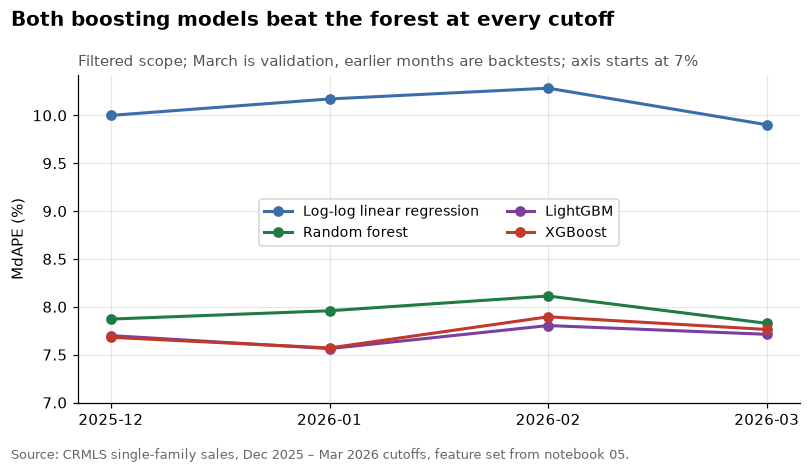

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for name in ORDER:
    ax.plot([month_label(m) for m in CUTOFFS], by_cutoff.loc[name, CUTOFFS], marker="o",
            color=COLORS[name], label=avm.DISPLAY_NAMES[name], linewidth=2)
ax.set_ylabel("MdAPE (%)")
ax.set_ylim(7, None)
ax.legend(fontsize=9, loc="center", ncols=2, bbox_to_anchor=(0.5, 0.55))
avm.finish_chart(fig, ax, "Both boosting models beat the forest at every cutoff",
                 "Filtered scope; March is validation, earlier months are backtests; axis starts at 7%",
                 "Source: CRMLS single-family sales, Dec 2025 – Mar 2026 cutoffs, feature set from notebook 05.")
plt.show()

,,MdAPE difference (pts),95% CI,Resamples favoring first (%)
Comparison,Month,,,
LightGBM − Random forest,2025-12,-0.17,-0.32 to -0.00,97.9
XGBoost − Random forest,2025-12,-0.19,-0.32 to -0.02,98.7
LightGBM − XGBoost,2025-12,+0.02,-0.13 to +0.15,42.9
LightGBM − Random forest,2026-01,-0.40,-0.63 to -0.19,99.9
XGBoost − Random forest,2026-01,-0.39,-0.62 to -0.21,100.0
LightGBM − XGBoost,2026-01,-0.01,-0.17 to +0.19,51.1
LightGBM − Random forest,2026-02,-0.31,-0.46 to -0.06,99.7
XGBoost − Random forest,2026-02,-0.22,-0.40 to -0.01,98.0
LightGBM − XGBoost,2026-02,-0.09,-0.21 to +0.09,81.2


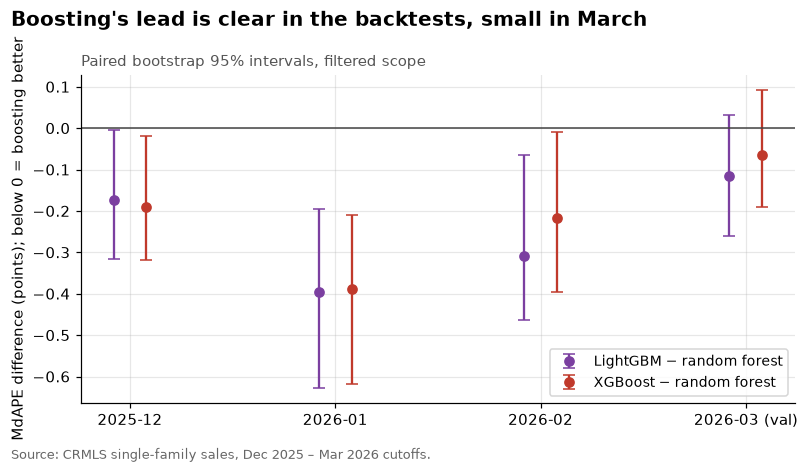

In [8]:
boot = bootstrap.copy()
boot["Comparison"] = boot["model"] + " − " + boot["versus"]
table = boot.assign(Month=boot["month"].map(month_label),
                    **{"MdAPE difference (pts)": boot["mdape_change"].map("{:+.2f}".format),
                       "95% CI": [f"{lo:+.2f} to {hi:+.2f}" for lo, hi in zip(boot["ci_low"], boot["ci_high"])],
                       "Resamples favoring first (%)": boot["share_favoring_model"].map("{:.1f}".format)})
display(table.set_index(["Comparison", "Month"])[["MdAPE difference (pts)", "95% CI",
                                                  "Resamples favoring first (%)"]])

fig, ax = plt.subplots(figsize=(7.5, 4.2))
for i, (model_a, model_b) in enumerate([(LIGHTGBM, FOREST), (XGBOOST, FOREST)]):
    rows = boot.query("model == @model_a and versus == @model_b").set_index("month").loc[CUTOFFS]
    x = np.arange(len(CUTOFFS)) + (i - 0.5) * 0.16
    ax.errorbar(x, rows["mdape_change"],
                yerr=[rows["mdape_change"] - rows["ci_low"], rows["ci_high"] - rows["mdape_change"]],
                fmt="o", capsize=4, color=COLORS[model_a], label=f"{model_a} − random forest")
ax.axhline(0, color="#444444", linewidth=1)
ax.set_xticks(range(len(CUTOFFS)), [month_label(m) + (" (val)" if m == VAL_MONTH else "") for m in CUTOFFS])
ax.set_ylabel("MdAPE difference (points); below 0 = boosting better")
ax.legend(fontsize=9, loc="lower right")
avm.finish_chart(fig, ax, "Boosting's lead is clear in the backtests, small in March",
                 "Paired bootstrap 95% intervals, filtered scope",
                 "Source: CRMLS single-family sales, Dec 2025 – Mar 2026 cutoffs.")
plt.show()

- **Boosting vs the forest.** Both boosters have the lowest MdAPE at every cutoff. In the backtests the lead is 0.17–0.40 points (LightGBM) and 0.19–0.39 points (XGBoost), with every interval below zero (LightGBM's December interval only just, at −0.32 to −0.00). On March validation it is 0.11 and 0.06 points, and both intervals include zero. That is consistent with a real but small advantage that March, by chance, shows less of. March cannot confirm it on its own.
- **LightGBM vs XGBoost.** The difference is 0.09 points or less at every cutoff, every interval includes zero, and the bootstrap favors LightGBM in only 43–82% of resamples. They are interchangeable on accuracy.
- **Other metrics.** On March, both boosters lead on R² (0.903–0.904 vs 0.887), MAE ($146K vs $155K) and the share within 20% (85.6–85.7% vs 84.8%).
- **All sales.** When the 1.2% of sales outside the price bounds are included, every tree model's R² falls below the log-log model's (0.69–0.70 for boosting, 0.65 for the forest, 0.73 for log-log). Trees cannot predict above the highest training price, and the excluded sales include the most expensive homes. Boosting extrapolates no better than the forest but loses less R² than it does. MdAPE barely moves for any model.
- **Stability.** Boosting's MdAPE ranges over 0.24–0.33 points across the four cutoffs, similar to the forest (0.29).

## 5. Fit, size and overfitting

The fitted pipelines from the March cutoff, saved the way the Week 9 app will save them (joblib, `compress=3`). Training MdAPE is on the same sales each model was fitted on, so the gap to March shows how much each model memorizes.

,Train MdAPE (%),March MdAPE (%),Gap (pts),Fit time (s),"Saved size (MB, joblib compress=3)",Load time (s)
model,,,,,,
Log-log linear regression,9.52,9.90,0.38,4,0.0,0.00
Random forest,5.65,7.83,2.18,20,267.9,1.29
LightGBM,6.15,7.71,1.56,28,6.8,0.04
XGBoost,6.36,7.76,1.40,3,4.2,0.02


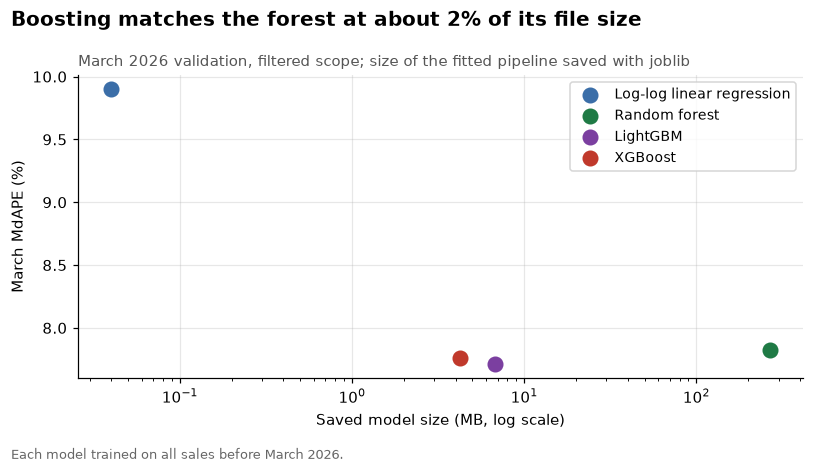

In [9]:
size_table = sizes.loc[ORDER].assign(gap=lambda t: t["MdAPE_pct"] - t["train_MdAPE_pct"])
display(pd.DataFrame({
    "Train MdAPE (%)": size_table["train_MdAPE_pct"].map("{:.2f}".format),
    "March MdAPE (%)": size_table["MdAPE_pct"].map("{:.2f}".format),
    "Gap (pts)": size_table["gap"].map("{:.2f}".format),
    "Fit time (s)": size_table["fit_seconds"].map("{:.0f}".format),
    "Saved size (MB, joblib compress=3)": size_table["size_mb"].map("{:,.1f}".format),
    "Load time (s)": size_table["load_seconds"].map("{:.2f}".format),
}, index=size_table.index))

fig, ax = plt.subplots(figsize=(7.5, 4.2))
for name in ORDER:
    ax.scatter(sizes.loc[name, "size_mb"], sizes.loc[name, "MdAPE_pct"], s=90, color=COLORS[name],
               label=avm.DISPLAY_NAMES[name], zorder=3)
ax.set_xscale("log")
ax.set_xlabel("Saved model size (MB, log scale)")
ax.set_ylabel("March MdAPE (%)")
ax.legend(fontsize=9, loc="upper right")
avm.finish_chart(fig, ax, "Boosting matches the forest at about 2% of its file size",
                 "March 2026 validation, filtered scope; size of the fitted pipeline saved with joblib",
                 "Each model trained on all sales before March 2026.")
plt.show()

The forest is 268 MB and takes 1.3 seconds to load. LightGBM (6.8 MB) and XGBoost (4.2 MB) are 40–65 times smaller and load in a few hundredths of a second. The forest also has the largest train-to-March gap (2.2 points): with 5-sale leaves and no depth limit, it fits its training sales more closely than boosting does, and gains less from it. XGBoost fits in 3 seconds with 500 trees. The selected LightGBM needs 28, mostly because of its 1,500 trees with 127 leaves.

## 6. Final model

Rule, stated in the setup cell: among the forest and the two tuned boosters, take the lowest March MdAPE. Any model within 0.1 points of it is tied, and ties go to the smallest saved model.

In [10]:
march = filtered.query("month == @VAL_MONTH").set_index("model")
best_mdape = march.loc[CANDIDATES, "MdAPE_pct"].min()
tied = [name for name in CANDIDATES if march.loc[name, "MdAPE_pct"] <= best_mdape + TOLERANCE]
chosen = min(tied, key=lambda name: sizes.loc[name, "size_mb"])
chosen_params = FOREST_PARAMS if chosen == FOREST else SELECTED_PARAMS[chosen]

FINAL_CONFIG = {
    "model": "XGBoost",
    "params": {"learning_rate": 0.1, "max_depth": 10, "n_estimators": 500, "min_child_weight": 20},
    "log_target": True,
    "features": {"name": "B without ratios",
                 "numeric": ["LivingArea", "LotSizeSquareFeet", "BedroomsTotal", "BathroomsTotalInteger",
                             "AgeAtSale", "Latitude", "Longitude"],
                 "categorical": ["City", "PostalCode", "SchoolDistrict"]},
}
assert FINAL_CONFIG["model"] == chosen and FINAL_CONFIG["params"] == chosen_params
assert FINAL_CONFIG["features"] == {"name": FEATURES.name, "numeric": list(FEATURES.numeric),
                                    "categorical": list(FEATURES.categorical)}
FINAL_CONFIG_PATH.write_text(json.dumps(FINAL_CONFIG, indent=2) + "\n")
print("Within 0.1 pt of the lowest March MdAPE:", ", ".join(tied))
print(f"Final model: {chosen} ({avm.describe_config(chosen_params, True)}), "
      f"March MdAPE {march.loc[chosen, 'MdAPE_pct']:.2f}%, {sizes.loc[chosen, 'size_mb']:.1f} MB")

Within 0.1 pt of the lowest March MdAPE: LightGBM, XGBoost
Final model: XGBoost (learning_rate=0.1, max_depth=10, n_estimators=500, min_child_weight=20, target=log price), March MdAPE 7.76%, 4.2 MB


## 7. Notes

- **Final model: XGBoost.** Learning rate 0.1, max depth 10, 500 trees, minimum child weight 20, log-price target, on Dataset B without the ratios. LightGBM is just as accurate. XGBoost wins the tie because it is smaller and faster to fit, not because it scores better. The plan named LightGBM as the primary model for its small files, but under the rule written before tuning, XGBoost's file is smaller still.
- **What notebook 07 does.** Before scoring April, refit every model (linear baseline, log-log, decision tree, forest, LightGBM, XGBoost) on all months through March with the configurations frozen here and in notebooks 04–05, and score April once. The lock-in commit comes first.
- **April's four re-reported sales** are dropped by the cleaning rule before scoring.
- **Not tried:** native categorical handling, subsampling (`subsample`, `colsample_bytree`), regularization terms, and early stopping on a slice of the training months. The light grid was the scope for this week. The tuning table suggests more trees and leaves would still help a little, but at 0.1-point scale, which March cannot resolve.

Files written: `results/advanced_tuning_grid.csv` (all 32 configurations), `results/advanced_model_metrics.csv` (every model × cutoff × scope), `results/advanced_bootstrap.csv`, `results/advanced_model_size.csv`, and `results/final_model_config.json`.